# E-Commerce Customer Segmentation & Recommendation Analysis

In this notebook, we analyze customer purchasing behavior using the **Online Retail** dataset, build **Recency, Frequency, and Monetary (RFM)** features, apply **K-Means** clustering to segment customers, visualize clusters in 2D, build a basic **cosine similarity** product recommendation function, and outline practical business recommendations for each segment.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("Set2")

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load and Clean the Transaction Dataset

We load `Online Retail.csv` (which is an Excel-formatted workbook with sheet name `Online Retail`). We remove cancelled orders (`InvoiceNo` starting with `C`), drop rows with missing `CustomerID` or `Description`, keep positive `Quantity` and `UnitPrice` values, format `CustomerID` cleanly as a string, and compute `TotalPrice` (`Quantity * UnitPrice`).

In [6]:
file_path = "Online Retail.csv"

# Read Excel workbook saved with .csv extension (fallback to CSV if converted later)
try:
    xls = pd.ExcelFile(file_path)
    df_raw = pd.read_excel(xls, sheet_name="Online Retail")
except Exception:
    df_raw = pd.read_csv(file_path, encoding="ISO-8859-1")

print("Raw dataset shape:", df_raw.shape)

# Remove cancelled invoices (InvoiceNo starting with 'C')
df = df_raw[~df_raw["InvoiceNo"].astype(str).str.startswith("C")].copy()

# Convert data types and filter invalid rows
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df_clean = df.dropna(
    subset=["CustomerID", "StockCode", "Description", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int).astype(str)
df_clean["Description"] = df_clean["Description"].astype(str).str.strip()
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["UnitPrice"] > 0)]

# Create total transaction value column
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print("Cleaned dataset shape:", df_clean.shape)
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Unique products:", df_clean["Description"].nunique())
df_clean.head()

Raw dataset shape: (541909, 8)
Cleaned dataset shape: (397884, 9)
Unique customers: 4338
Unique products: 3866


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 2. Customer-Level Feature Table and RFM Features

We group the cleaned transaction data by `CustomerID` to build a customer-level feature table containing:
* **Recency_Days**: Days since the customer's most recent purchase relative to `max(InvoiceDate) + 1 day` (lower means more recent).
* **Frequency**: Total number of unique invoices (`InvoiceNo`) placed by the customer.
* **Monetary**: Total spending (`TotalPrice`) across all orders.
* **Total_Items**: Total product units purchased.
* **Avg_Order_Value**: Average spend per order (`Monetary / Frequency`).

In [7]:
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_df = df_clean.groupby("CustomerID").agg(
    Last_Purchase_Date=("InvoiceDate", "max"),
    Recency_Days=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
    Total_Items=("Quantity", "sum")
).reset_index()

customer_df["Avg_Order_Value"] = customer_df["Monetary"] / customer_df["Frequency"]

print("Customer-level feature table shape:", customer_df.shape)
customer_df[["CustomerID", "Recency_Days", "Frequency", "Monetary", "Total_Items", "Avg_Order_Value"]].head()

Customer-level feature table shape: (4338, 7)


,CustomerID,Recency_Days,Frequency,Monetary,Total_Items,Avg_Order_Value
0,12346,326,1,77183.60,74215,77183.600000
1,12347,2,7,4310.00,2458,615.714286
2,12348,75,4,1797.24,2341,449.310000
3,12349,19,1,1757.55,631,1757.550000
4,12350,310,1,334.40,197,334.400000


## 3. Feature Scaling and Preprocessing

Because `Recency_Days`, `Frequency`, and `Monetary` have very different numeric ranges, we standardize them using `StandardScaler` so all three RFM features contribute evenly to K-Means distance calculations.

In [8]:
rfm_cols = ["Recency_Days", "Frequency", "Monetary"]

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(customer_df[rfm_cols])

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency_Scaled", "Frequency_Scaled", "Monetary_Scaled"],
    index=customer_df.index
)

print("Scaled RFM summary:")
print(rfm_scaled_df.describe().round(2))

Scaled RFM summary:
       Recency_Scaled  Frequency_Scaled  Monetary_Scaled
count         4338.00           4338.00          4338.00
mean             0.00              0.00             0.00
std              1.00              1.00             1.00
min             -0.92             -0.43            -0.23
25%             -0.75             -0.43            -0.19
50%             -0.42             -0.30            -0.15
75%              0.49              0.09            -0.04
max              2.81             26.60            30.95


## 4. Elbow Method and Silhouette Analysis

We test `k` values from `2` to `6` using:
* **Elbow Method (Inertia)**: Measures within-cluster sum of squares; we look for the bend where adding more clusters yields diminishing returns.
* **Silhouette Score**: Measures how well-separated clusters are (higher values indicate clearer separation).

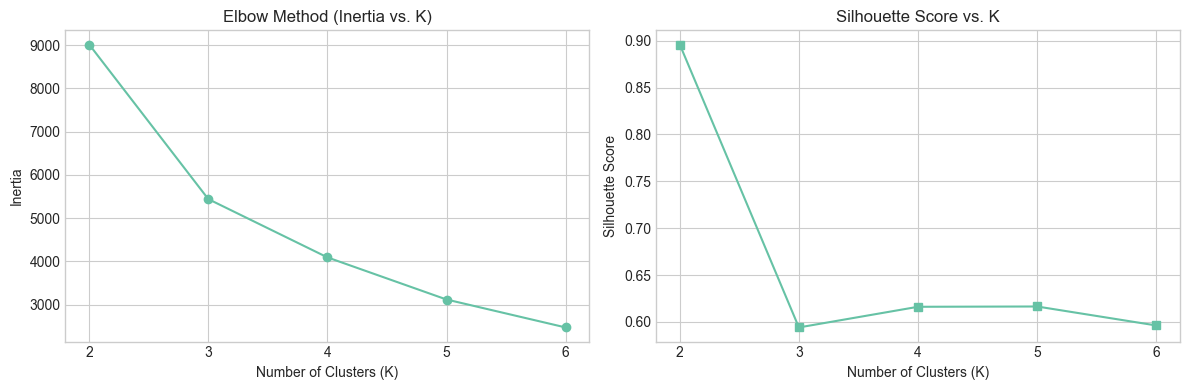

K=2 -> Inertia: 9012.6, Silhouette Score: 0.8958
K=3 -> Inertia: 5439.3, Silhouette Score: 0.5942
K=4 -> Inertia: 4092.1, Silhouette Score: 0.6162
K=5 -> Inertia: 3118.3, Silhouette Score: 0.6165
K=6 -> Inertia: 2472.6, Silhouette Score: 0.5963


In [9]:
k_values = [2, 3, 4, 5, 6]
inertias = []
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method (Inertia vs. K)")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(k_values)

axes[1].plot(k_values, silhouette_scores, marker="s")
axes[1].set_title("Silhouette Score vs. K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_values)

plt.tight_layout()
plt.show()

for k, inertia, sil in zip(k_values, inertias, silhouette_scores):
    print(f"K={k} -> Inertia: {inertia:.1f}, Silhouette Score: {sil:.4f}")

## 5. K-Means Segmentation and Business Segment Labels

We fit K-Means with `k = 4` and assign clear business labels based on each cluster's RFM profile:
* **Champions**
* **Regular Customers**
* **Occasional Buyers**
* **At-Risk Customers**

In [10]:
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
customer_df["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Rank clusters dynamically from highest value/engagement to lowest
cluster_rank = customer_df.groupby("Cluster").agg(
    Avg_Recency=("Recency_Days", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).reset_index()

cluster_rank["Score"] = (
    cluster_rank["Avg_Monetary"].rank()
    + cluster_rank["Avg_Frequency"].rank()
    - cluster_rank["Avg_Recency"].rank()
)
cluster_rank = cluster_rank.sort_values("Score", ascending=False).reset_index(drop=True)

segment_names = [
    "Champions",
    "Regular Customers",
    "Occasional Buyers",
    "At-Risk Customers"
]

cluster_map = {int(row["Cluster"]): segment_names[i] for i, row in cluster_rank.iterrows()}
customer_df["Segment"] = customer_df["Cluster"].map(cluster_map)

print("Segment counts:")
print(customer_df["Segment"].value_counts())
customer_df[["CustomerID", "Recency_Days", "Frequency", "Monetary", "Cluster", "Segment"]].head(10)

Segment counts:
Segment
Occasional Buyers    3054
At-Risk Customers    1067
Regular Customers     204
Champions              13
Name: count, dtype: int64


,CustomerID,Recency_Days,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,3,Regular Customers
1,12347,2,7,4310.00,0,Occasional Buyers
2,12348,75,4,1797.24,0,Occasional Buyers
3,12349,19,1,1757.55,0,Occasional Buyers
4,12350,310,1,334.40,1,At-Risk Customers
5,12352,36,8,2506.04,0,Occasional Buyers
6,12353,204,1,89.00,1,At-Risk Customers
7,12354,232,1,1079.40,1,At-Risk Customers
8,12355,214,1,459.40,1,At-Risk Customers
9,12356,23,3,2811.43,0,Occasional Buyers


## 6. 2D Customer Cluster Visualization

We visualize customer segments in two 2D views (`Frequency` vs. `Monetary` and `Recency_Days` vs. `Monetary`) to inspect how behavioral groups differ.

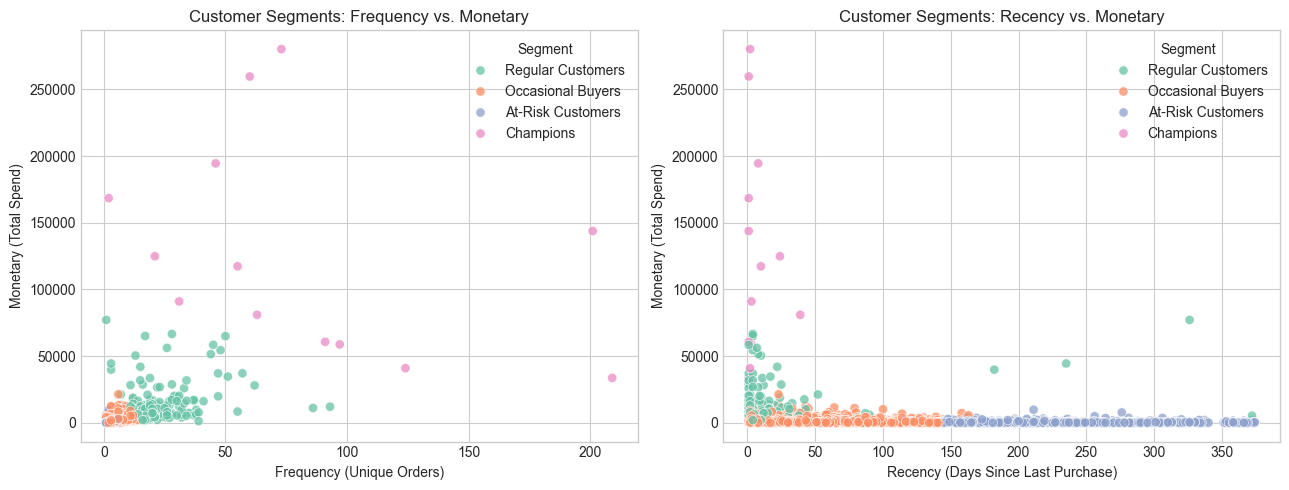

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=customer_df,
    x="Frequency",
    y="Monetary",
    hue="Segment",
    alpha=0.75,
    s=45,
    ax=axes[0]
)
axes[0].set_title("Customer Segments: Frequency vs. Monetary")
axes[0].set_xlabel("Frequency (Unique Orders)")
axes[0].set_ylabel("Monetary (Total Spend)")

sns.scatterplot(
    data=customer_df,
    x="Recency_Days",
    y="Monetary",
    hue="Segment",
    alpha=0.75,
    s=45,
    ax=axes[1]
)
axes[1].set_title("Customer Segments: Recency vs. Monetary")
axes[1].set_xlabel("Recency (Days Since Last Purchase)")
axes[1].set_ylabel("Monetary (Total Spend)")

plt.tight_layout()
plt.show()

## 7. Business-Friendly Customer Segment Profiles

Below is a summary table of each segment's customer count, average recency, average frequency, average total spend, and average order value.

In [12]:
segment_profiles = customer_df.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency_Days=("Recency_Days", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Avg_Order_Value=("Avg_Order_Value", "mean")
).round(2).reset_index()

segment_profiles

,Segment,Customer_Count,Avg_Recency_Days,Avg_Frequency,Avg_Monetary,Avg_Order_Value
0,At-Risk Customers,1067,248.08,1.55,480.62,314.81
1,Champions,13,7.38,82.54,127338.31,8570.73
2,Occasional Buyers,3054,43.70,3.68,1359.05,376.76
3,Regular Customers,204,15.50,22.33,12709.09,1080.41


## 8. Basic Product Recommendation Function Using Cosine Similarity

We build a customer-by-product quantity matrix using the top 150 most purchased products, compute **cosine similarity** between products, and define `recommend_products()` to return the top similar items for any given product name.

In [13]:
# Select top 150 products by total quantity sold to keep similarity fast and clear
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(150)
    .index
)

top_df = df_clean[df_clean["Description"].isin(top_products)]

# Customer-by-product purchase matrix
user_item_matrix = top_df.pivot_table(
    index="CustomerID",
    columns="Description",
    values="Quantity",
    aggfunc="sum",
    fill_value=0
)

# Cosine similarity between products (columns)
item_sim_matrix = cosine_similarity(user_item_matrix.T)
item_sim_df = pd.DataFrame(
    item_sim_matrix,
    index=user_item_matrix.columns,
    columns=user_item_matrix.columns
)

def recommend_products(product_name, top_n=5):
    """Return top_n similar products based on cosine similarity."""
    matches = [col for col in item_sim_df.columns if product_name.lower() in col.lower()]
    if not matches:
        return f"No matching product found in top products for '{product_name}'."

    selected_product = matches[0]
    similar_items = (
        item_sim_df[selected_product]
        .drop(labels=[selected_product])
        .sort_values(ascending=False)
        .head(top_n)
        .reset_index()
    )
    similar_items.columns = ["Recommended_Product", "Cosine_Similarity"]
    similar_items["Cosine_Similarity"] = similar_items["Cosine_Similarity"].round(3)
    return selected_product, similar_items

product_query, recs_df = recommend_products("WHITE HANGING HEART T-LIGHT HOLDER", top_n=5)
print(f"Top recommendations for: {product_query}")
recs_df

Top recommendations for: WHITE HANGING HEART T-LIGHT HOLDER


,Recommended_Product,Cosine_Similarity
0,GIN + TONIC DIET METAL SIGN,0.750
1,RED HANGING HEART T-LIGHT HOLDER,0.659
2,HEART OF WICKER LARGE,0.629
3,HEART OF WICKER SMALL,0.628
4,FAIRY CAKE FLANNEL ASSORTED COLOUR,0.590


## 9. Business Recommendations by Customer Segment

We map each customer segment to targeted retention, cross-selling, and reactivation actions based on its RFM metrics.

In [14]:
segment_actions = {
    "Champions": (
        "Very low recency, high order frequency, and highest spend. Reward with VIP perks, "
        "early access to new collections, and loyalty incentives to keep them engaged."
    ),
    "Regular Customers": (
        "Recent and steady repeat buyers with strong order values. Recommend complementary "
        "products via cosine similarity and offer multi-item bundles to increase order size."
    ),
    "Occasional Buyers": (
        "Largest customer group with moderate spend and lower order frequency. Use targeted "
        "email/app promotions, seasonal offers, and personalized product suggestions to build repeat habits."
    ),
    "At-Risk Customers": (
        "High recency (long time since last purchase) and low order frequency. Run win-back "
        "campaigns with limited-time discounts and relevant product reminders before they churn."
    ),
}

business_recommendations_df = segment_profiles.copy()
business_recommendations_df["Business_Recommendation"] = business_recommendations_df["Segment"].map(
    lambda s: segment_actions.get(s, "Track behavior and run targeted campaigns.")
)

for _, row in business_recommendations_df.iterrows():
    print(f"Segment: {row['Segment']} ({int(row['Customer_Count'])} customers)")
    print(f"  Avg Recency: {row['Avg_Recency_Days']} days | Avg Frequency: {row['Avg_Frequency']} | Avg Monetary: {row['Avg_Monetary']} | Avg AOV: {row['Avg_Order_Value']}")
    print(f"  Action: {row['Business_Recommendation']}\n")

Segment: At-Risk Customers (1067 customers)
  Avg Recency: 248.08 days | Avg Frequency: 1.55 | Avg Monetary: 480.62 | Avg AOV: 314.81
  Action: High recency (long time since last purchase) and low order frequency. Run win-back campaigns with limited-time discounts and relevant product reminders before they churn.

Segment: Champions (13 customers)
  Avg Recency: 7.38 days | Avg Frequency: 82.54 | Avg Monetary: 127338.31 | Avg AOV: 8570.73
  Action: Very low recency, high order frequency, and highest spend. Reward with VIP perks, early access to new collections, and loyalty incentives to keep them engaged.

Segment: Occasional Buyers (3054 customers)
  Avg Recency: 43.7 days | Avg Frequency: 3.68 | Avg Monetary: 1359.05 | Avg AOV: 376.76
  Action: Largest customer group with moderate spend and lower order frequency. Use targeted email/app promotions, seasonal offers, and personalized product suggestions to build repeat habits.

Segment: Regular Customers (204 customers)
  Avg Recency: 1